In [8]:
from cryoevap.solar import declinacion, angulo_horario, altitud_solar, irradiancia_normal, irradiancia_techo

print(declinacion(192))
print(angulo_horario(11))
print(altitud_solar(40, declinacion(192), angulo_horario(11)))
print(declinacion(15))
print(altitud_solar(-23, declinacion(15), angulo_horario(12)))

22.107748812505374
-15.0
68.04116145287435
-21.269473910221816
88.26947391022199


In [9]:
A, B, C = 1085, 0.206, 0.135   # valores de julio del ejemplo de clase

# Ejemplo de clase: 40N, 11 de julio, 11:00 solar
b1 = altitud_solar(40, declinacion(192), angulo_horario(11))
print(irradiancia_normal(A, B, b1))

# Tabla 3-4 del Cengel: 40N, 21 de julio, mediodía solar
b2 = altitud_solar(40, declinacion(202), angulo_horario(12))
print(irradiancia_normal(A, B, b2))
print(irradiancia_techo(A, B, C, b2))

# De noche
print(irradiancia_normal(A, B, -10))

868.8943322970379
871.9405939843277
939.3418234592226
0.0


In [10]:
from cryoevap.solar import irradiancia_pared

A, B, C = 1085, 0.206, 0.135

# 40N, 21 de julio, mediodía solar
b2 = altitud_solar(40, declinacion(202), angulo_horario(12))
for rho in (0.0, 0.2, 0.4):
    print(rho, irradiancia_pared(A, B, C, rho, b2))

print(irradiancia_techo(A, B, C, b2))

# De noche
print(irradiancia_pared(A, B, C, 0.2, -10))

0.0 151.77020427285564
0.2 245.7043866187779
0.4 339.63856896470014
939.3418234592226
0.0


In [11]:
import numpy as np
import pandas as pd

A, B, C = 1085, 0.206, 0.135
horas = np.arange(6, 13)                       # 6:00 a 12:00 solares
directa_tabla = np.array([434, 656, 762, 818, 850, 866, 871])
horizontal_tabla = np.array([115, 320, 528, 702, 838, 922, 949])

b = altitud_solar(40, declinacion(202), angulo_horario(horas))
directa_modelo = irradiancia_normal(A, B, b)
techo_modelo = irradiancia_techo(A, B, C, b)

# Tabla 3-4 del Cengel: 40N, 21 de julio, mediodía solar
tabla = pd.DataFrame({
    "Hora solar": horas,
    "Directa modelo": directa_modelo.round().astype(int),
    "Directa tabla": directa_tabla,
    "Dif. directa [%]": (100*(directa_modelo - directa_tabla)/directa_tabla).round(1),
    "Horizontal modelo": techo_modelo.round().astype(int),
    "Horizontal tabla": horizontal_tabla,
    "Dif. horizontal [%]": (100*(techo_modelo - horizontal_tabla)/horizontal_tabla).round(1),
})
tabla

,Hora solar,Directa modelo,Directa tabla,Dif. directa [%],Horizontal modelo,Horizontal tabla,Dif. horizontal [%]
0,6,433,434,-0.1,156,115,35.5
1,7,657,656,0.1,358,320,11.9
2,8,762,762,0.0,548,528,3.7
3,9,819,818,0.1,710,702,1.1
4,10,851,850,0.1,834,838,-0.4
5,11,867,866,0.1,913,922,-1.0
6,12,872,871,0.1,939,949,-1.0


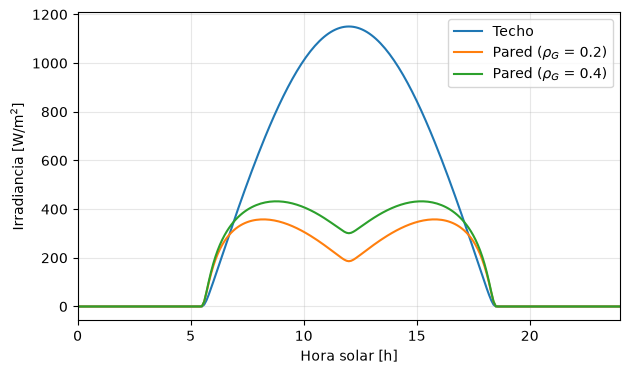

1150.3471597267442 12.0


In [15]:
import matplotlib.pyplot as plt

# Mejillones, 21 de enero, constantes ASHRAE de enero (McQuiston, Tabla 7-2)
L = -23.1                            # latitud [grados], aprox.
d = 21
A, B, C = 381.2 * 3.1546, 0.141, 0.103   # A de Btu/h ft2 a W/m2

horas = np.linspace(0, 24, 241)
b = altitud_solar(L, declinacion(d), angulo_horario(horas))
roof = irradiancia_techo(A, B, C, b)

plt.figure(figsize=(7, 4))
plt.plot(horas, roof, label="Techo")
for rho in (0.2, 0.4):
    plt.plot(horas, irradiancia_pared(A, B, C, rho, b),
             label=f"Pared ($\\rho_G$ = {rho})")
plt.xlabel("Hora solar [h]")
plt.ylabel("Irradiancia [W/m$^2$]")
plt.xlim(0, 24)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(roof.max(), horas[roof.argmax()])

## Usando la base de datos de INIA para el 21 de diciembre 2025

Esa fecha se observo la curva de la radacion plana, asi que se suma como día de referencia para radiación extrema

In [16]:
from cryoevap.solar import hora_solar, ecuacion_tiempo

print("EoT 21 dic [min]:", ecuacion_tiempo(355))
print("INIA 16:00  ->", hora_solar(16, 355, 70.443333, -4))
print("DMC 16.83 h ->", hora_solar(16.83, 355, 70.443333, 0))

EoT 21 dic [min]: 1.0291296184126901
INIA 16:00  -> 15.320929960306879
DMC 16.83 h -> 12.150929960306877


In [17]:
ruta = "C:/Users/isido/OneDrive/Escritorio/Proyecto-10/data/mejillones_inia_2025-12-21.csv"

df = pd.read_csv(ruta, skiprows=5, nrows=24, encoding="utf-8")
df = df.iloc[:, :4]
df.columns = ["hora_inia", "T_C", "rad_Wm2", "viento_kmh"]

df["hora_inia"] = pd.to_datetime(df["hora_inia"], format="%d-%m-%Y %H:%M")
df["viento_ms"] = df["viento_kmh"] / 3.6
df["T_K"] = df["T_C"] + 273.15

print(df.head())
print(df.dtypes)

            hora_inia   T_C  rad_Wm2  viento_kmh  viento_ms     T_K
0 2025-12-21 00:00:00  18.8      0.0        12.8   3.555556  291.95
1 2025-12-21 01:00:00  18.0      0.0        14.7   4.083333  291.15
2 2025-12-21 02:00:00  17.2      0.0        13.9   3.861111  290.35
3 2025-12-21 03:00:00  16.8      0.0        12.5   3.472222  289.95
4 2025-12-21 04:00:00  15.8      0.0        11.6   3.222222  288.95
hora_inia     datetime64[us]
T_C                  float64
rad_Wm2              float64
viento_kmh           float64
viento_ms            float64
T_K                  float64
dtype: object


In [18]:
df["hora_reloj"] = df["hora_inia"].dt.hour + df["hora_inia"].dt.minute / 60
df["t_solar"] = hora_solar(df["hora_reloj"] + 0.5, 355, 70.443333, -4)

print(df[["hora_inia", "T_C", "rad_Wm2", "t_solar"]])

             hora_inia   T_C  rad_Wm2   t_solar
0  2025-12-21 00:00:00  18.8      0.0  -0.17907
1  2025-12-21 01:00:00  18.0      0.0   0.82093
2  2025-12-21 02:00:00  17.2      0.0   1.82093
3  2025-12-21 03:00:00  16.8      0.0   2.82093
4  2025-12-21 04:00:00  15.8      0.0   3.82093
5  2025-12-21 05:00:00  15.5      0.0   4.82093
6  2025-12-21 06:00:00  16.2     79.7   5.82093
7  2025-12-21 07:00:00  19.4    284.2   6.82093
8  2025-12-21 08:00:00  21.9    562.8   7.82093
9  2025-12-21 09:00:00  23.9    796.5   8.82093
10 2025-12-21 10:00:00  23.5    950.7   9.82093
11 2025-12-21 11:00:00  24.0   1040.0  10.82093
12 2025-12-21 12:00:00  25.4   1068.6  11.82093
13 2025-12-21 13:00:00  26.3   1066.8  12.82093
14 2025-12-21 14:00:00  26.6   1004.7  13.82093
15 2025-12-21 15:00:00  26.5    810.2  14.82093
16 2025-12-21 16:00:00  26.8    530.0  15.82093
17 2025-12-21 17:00:00  26.4    314.6  16.82093
18 2025-12-21 18:00:00  24.5    135.4  17.82093
19 2025-12-21 19:00:00  22.0      7.0  1

In [2]:
import importlib
import cryoevap.solar, cryoevap.datos_solar
importlib.reload(cryoevap.solar); importlib.reload(cryoevap.datos_solar)
from cryoevap.datos_solar import cargar_datos
from cryoevap.solar import perfil_radiacion

ruta = "C:/Users/isido/OneDrive/Escritorio/Proyecto-10/data/explorador_solar_mejillones_2016-12-21.csv"
datos = cargar_datos(ruta)
print(datos.shape)                       # (24, 7)

for t, t0 in [(13*3600, 0), (13.5*3600, 0), (37*3600, 0)]:
    print(t/3600, [round(float(x), 2) for x in perfil_radiacion(t, t0, datos)])

(24, 7)
13.0 [1074.84, 54.42, 1125.86]
13.5 [1070.43, 54.16, 1095.91]
37.0 [1074.84, 54.42, 1125.86]


In [4]:
importlib.reload(cryoevap.solar)
from cryoevap.solar import I_pared, I_techo, rad_directa, rad_difusa, beta1

print(beta1(13*3600, 0))      # unos 85 a 86 grados
for h in [7, 9, 13, 17, 20]:
    t = h * 3600
    print(h, [round(float(x), 1) for x in
          (rad_directa(t, 0, datos)[0], rad_difusa(t, 0, datos)[0],
           I_pared(t, 0, datos), I_techo(t, 0, datos))])

85.56877993888426
7 [231.6, 38.2, 269.7, 206.4]
9 [244.6, 93.5, 338.2, 687.8]
13 [26.4, 139.8, 166.2, 1125.9]
17 [259.8, 76.9, 336.6, 535.7]
20 [0.0, 0.0, 0.0, 0.0]
